# 4 · Did the models learn ripening or the season?

The only annotated run (series 1) lasted from 30 March to 2 August 2023. The sausages ripened in a traditional attic
without climate control, so **temperature rose together with the ripening phase**. A model can then reach a high score
by recognising "it is summer" instead of "the sausage is ripe". The score on series 1 cannot reveal this, because there
season and phase always go together.

The unannotated **series 2** (31 July 2023 to 3 April 2024: summer → winter → spring) can, even without labels:
ripening only moves forward, so the predicted phase must rise over time. A temperature-driven model predicts late
phases in August and falls back to early ones in winter.

**Using temperature without learning the season.** `temperature_difference` uses the probe temperatures *relative to the
air* (the seasonal level cancels out; a moist sausage stays cooler than the air through evaporation). The day/night swing
of the difference is still larger in summer, which `+augmentation` addresses: per training window a random temperature
offset, scaled swings and mirrored swings (training data only; `AUGMENTATION` in `ml_core/training.py`).

This notebook trains every model with each variant and compares
* **series 1, balanced accuracy**: leave-one-sausage-out, as in notebook 3;
* **series 2, phase order ρ**: rank correlation of time and predicted phase (+1 = always advancing, negative = backwards);
* **series 2, backwards share**: share of time the predicted phase lies below one reached earlier.

Caveat: series 2 may also ripen at a different pace (cold winter), so ρ says whether phases advance, not whether they are timed right.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root, so ml_core is importable
import matplotlib.pyplot as plt
import pandas as pd
from ml_core import data
from ml_core.training import FEATURE_SETS, PROGRESSION_UNTIL, compare_feature_sets, load_windows
pd.set_option("display.width", 200)

In [2]:
CONVERTED_DIR = data.CONVERTED_DIR
WINDOW_SIZE, STRIDE = 10, 2
VARIANTS = list(FEATURE_SETS) + ["temperature_difference+augmentation"]
QUICK = False
N_JOBS = -1          # all fits (variants × models × folds) share one pool of worker processes

In [3]:
windows = load_windows(CONVERTED_DIR, window_size=WINDOW_SIZE, stride=STRIDE)
unannotated = load_windows(CONVERTED_DIR, "series_2_*.csv", WINDOW_SIZE, STRIDE, annotated=False, classes=windows.classes)
pd.concat([windows.summary(), unannotated.summary()])[["recording", "windows", "from", "to"]]

series_1_sausage_1: 41,462 rows → 20,727 windows


series_1_sausage_2: 41,479 rows → 20,735 windows
series_1_sausage_3: 41,468 rows → 20,730 windows
series_1_sausage_4: 41,472 rows → 20,732 windows
series_1_sausage_5: 41,465 rows → 20,728 windows


series_2_sausage_1: 79,919 rows → 39,955 windows
series_2_sausage_2: 79,903 rows → 39,947 windows
series_2_sausage_3: 79,915 rows → 39,953 windows
series_2_sausage_4: 79,920 rows → 39,956 windows
series_2_sausage_5: 79,930 rows → 39,961 windows


,recording,windows,from,to
0,series_1_sausage_1,20727,2023-03-30 00:33:38.051909+00:00,2023-08-02 23:56:34.268438+00:00
1,series_1_sausage_2,20735,2023-03-30 00:33:38.051909+00:00,2023-08-02 23:43:26.013334+00:00
2,series_1_sausage_3,20730,2023-03-30 00:38:00.000000+00:00,2023-08-02 23:58:00.000000+00:00
3,series_1_sausage_4,20732,2023-03-30 00:37:55.818346+00:00,2023-08-02 23:55:25.481812+00:00
4,series_1_sausage_5,20728,2023-03-30 00:33:38.051909+00:00,2023-08-02 23:49:39.000000+00:00
0,series_2_sausage_1,39955,2023-07-31 22:36:39.560983+00:00,2024-04-03 06:49:51.257998+00:00
1,series_2_sausage_2,39947,2023-07-31 22:31:36.026797+00:00,2024-04-03 06:49:51.257998+00:00
2,series_2_sausage_3,39953,2023-07-31 22:38:00.000000+00:00,2024-04-03 06:50:28.017027+00:00
3,series_2_sausage_4,39956,2023-07-31 22:35:28.367609+00:00,2024-04-03 06:51:33.172636+00:00
4,series_2_sausage_5,39961,2023-07-31 22:35:05.696803+00:00,2024-04-03 06:49:51.257998+00:00


## Temperature over both runs: the confound in one picture (top), and what remains relative to the air (bottom)

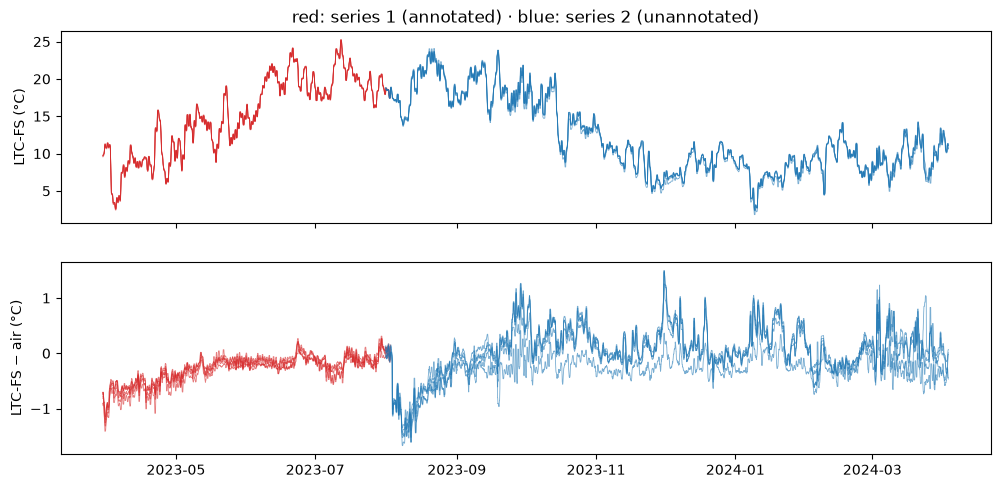

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for w, colour in ((windows, "tab:red"), (unannotated, "tab:blue")):
    for rec, raw in w.raw.items():
        t = raw[raw["sensor"] == "ltcfs"]
        ts = pd.to_datetime(t["timestamp"])
        axes[0].plot(ts, t["ltcfs_temperature"].rolling(50, min_periods=1).median(), color=colour, lw=.6, alpha=.6)
        axes[1].plot(ts, t["ltcfs_temperature_diff"].rolling(50, min_periods=1).median(), color=colour, lw=.6, alpha=.6)
axes[0].set(ylabel="LTC-FS (°C)", title="red: series 1 (annotated) · blue: series 2 (unannotated)")
axes[1].set(ylabel="LTC-FS − air (°C)")
plt.show()

In [5]:
table, progressions = compare_feature_sets(windows, unannotated, VARIANTS, quick=QUICK, n_jobs=N_JOBS)
table

90 fits (5 variants × 3 models × folds) in parallel …


original · Logistic Regression: balanced acc 0.779 (folds 0.72, 0.81, 0.76, 0.75, 0.86)


original · Random Forest: balanced acc 0.749 (folds 0.71, 0.82, 0.83, 0.62, 0.78)


original · MLP (neural net): balanced acc 0.707 (folds 0.67, 0.73, 0.80, 0.66, 0.67)


no_temperature · Logistic Regression: balanced acc 0.726 (folds 0.63, 0.77, 0.68, 0.74, 0.81)


no_temperature · Random Forest: balanced acc 0.699 (folds 0.60, 0.83, 0.81, 0.51, 0.74)


... (5 outputs left out)

temperature_difference · MLP (neural net): balanced acc 0.682 (folds 0.61, 0.71, 0.74, 0.70, 0.64)
temperature_difference+augmentation · Logistic Regression: balanced acc 0.715 (folds 0.60, 0.78, 0.61, 0.80, 0.78)


temperature_difference+augmentation · Random Forest: balanced acc 0.707 (folds 0.61, 0.82, 0.81, 0.57, 0.73)


temperature_difference+augmentation · MLP (neural net): balanced acc 0.664 (folds 0.60, 0.72, 0.69, 0.68, 0.63)


features  series 1: balanced acc  ± std  series 2: phase order ρ  series 2: backwards share
variant                             model                                                                                                           
original                            Logistic Regression        29                   0.779  0.050                    0.647                      0.885
                                    Random Forest              29                   0.749  0.078                    0.541                      0.983
                                    MLP (neural net)           29                   0.707  0.052                    0.644                      0.974
no_temperature                      Logistic Regression        17                   0.726  0.065                    0.838                      0.574
                                    Random Forest              17                   0.699  0.124                    0.774                      0.642
                                    MLP (neural net)           17                   0.703  0.096                    0.761                      0.656
moisture_conductivity               Logistic Regression        12                   0.718  0.105                    0.811                      0.634
                                    Random Forest              12                   0.648  0.065                    0.769                      0.641
                                    MLP (neural net)           12                   0.690  0.088                    0.779                      0.655
temperature_difference              Logistic Regression        24                   0.713  0.084                    0.796                      0.695
                                    Random Forest              24                   0.706  0.096                    0.767                      0.634
                                    MLP (neural net)           24                   0.682  0.048                    0.809                      0.687
temperature_difference+augmentation Logistic Regression        24                   0.715  0.087                    0.795                      0.696
                                    Random Forest              24                   0.707  0.102                    0.770                      0.631
                                    MLP (neural net)           24                   0.664  0.042                    0.826                      0.634

## Predicted phase on series 2 per feature set (smoothed over one day)

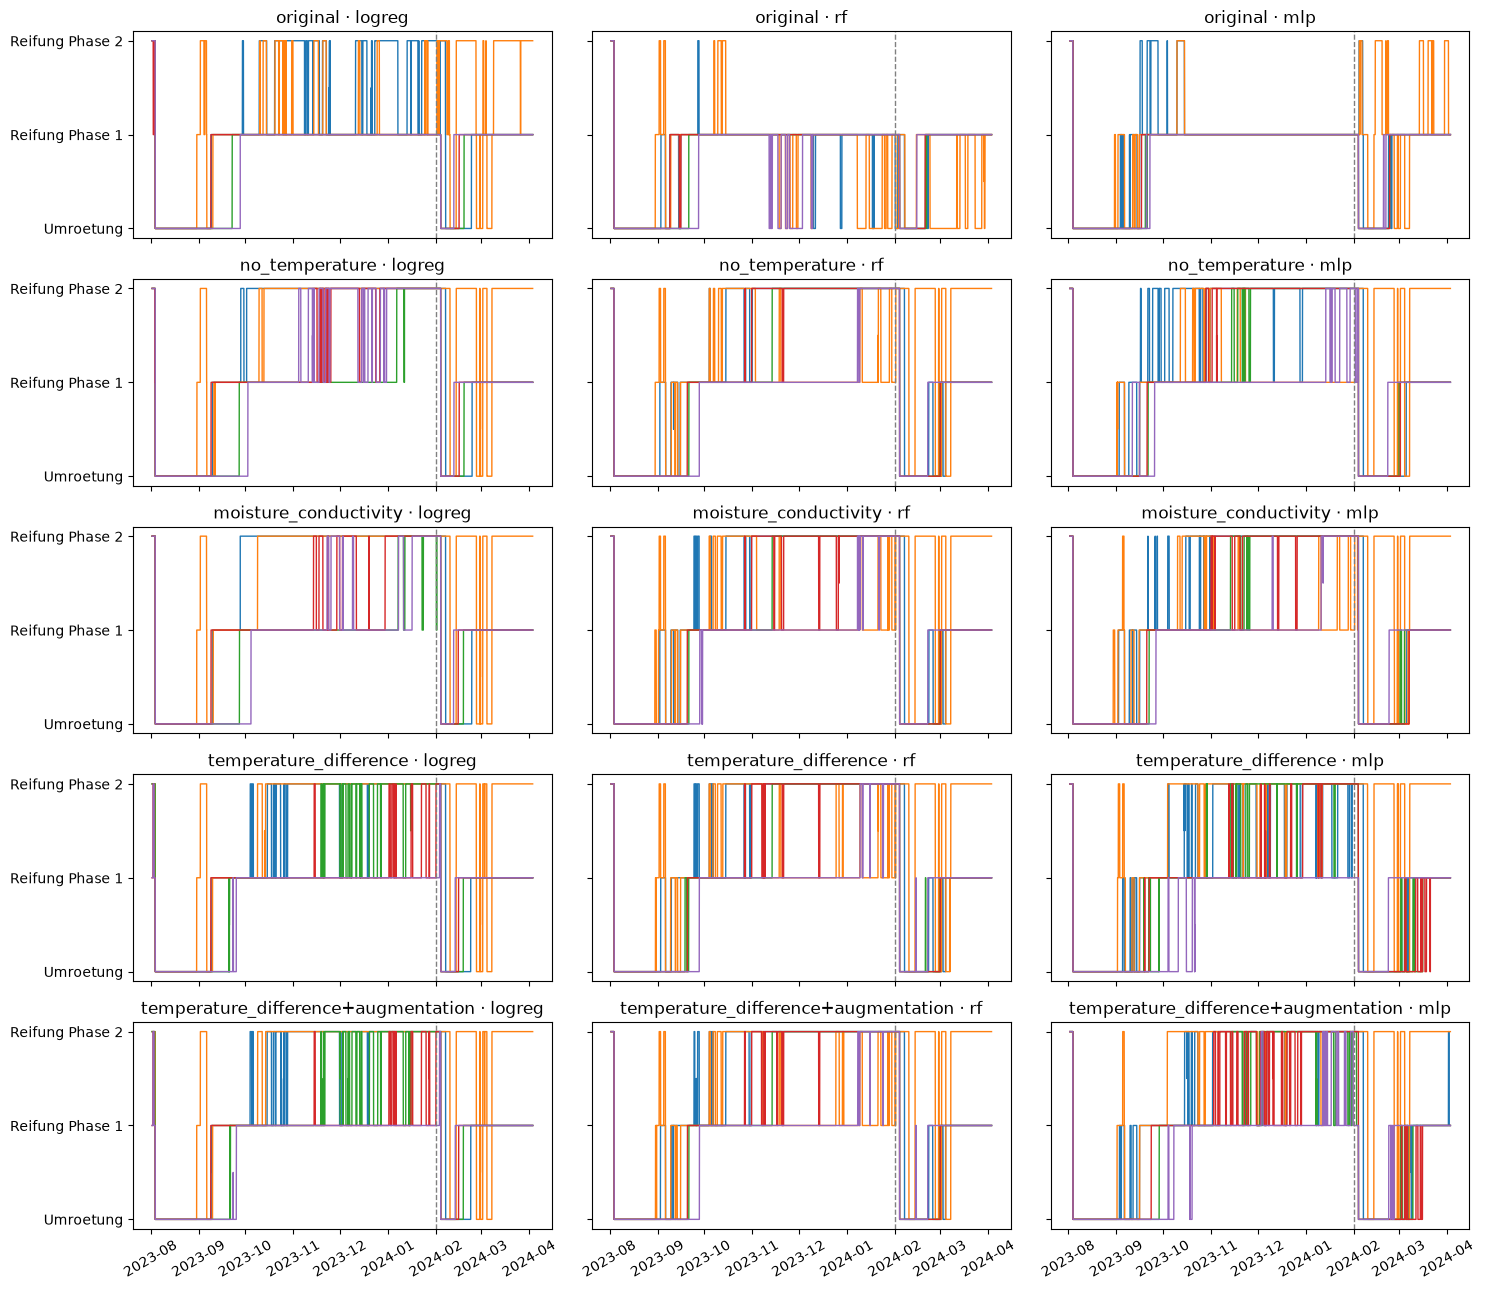

In [6]:
fsets = VARIANTS
keys = sorted({k for _, k in progressions}, key=["logreg", "rf", "mlp"].index)
fig, axes = plt.subplots(len(fsets), len(keys), figsize=(15, 2.6 * len(fsets)), sharex=True, sharey=True, squeeze=False)
for i, fs in enumerate(fsets):
    for j, key in enumerate(keys):
        ax = axes[i][j]
        for rec, s in progressions[(fs, key)].items():
            ax.plot(s.index, s.values, lw=1)
        if PROGRESSION_UNTIL:
            ax.axvline(pd.Timestamp(PROGRESSION_UNTIL), color="grey", ls="--", lw=1)
        ax.set(title=f"{fs} · {key}", yticks=range(len(windows.classes)), yticklabels=windows.classes)
        ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

The dashed line marks `PROGRESSION_UNTIL`: from early February 2024 the LSE01 moisture of series 2 jumps from about 7 % to
22 % and all models fall back. The probes were probably moved or re-inserted (there is no log), so ρ and the backwards
share only score the time before it.

**How to read it:** a variant is only trustworthy if it scores well on series 1 *and* advances on series 2.
The default for notebooks 2 and 3 is `DEFAULT_FEATURE_SET` in `ml_core/training.py`; augmentation is switched on with
`AUGMENT = True` in notebook 3. Change them if the results favour another variant, then re-run notebooks 2 and 3.

**Limit:** the butcher annotated when the whole batch reached each phase, so the labels describe ripening, but in
series 1 ripening and the rising temperature happen together. Only the choice of inputs (the sausage's state, not the
season) decides which of the two a model learns, and series 2 is the only available check of that choice.